In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from skimage.metrics import structural_similarity as ssim

from jepa_cxr.corruptions import CORRUPTIONS, corrupt

SAMPLE_DIR = Path("../data/samples")
SIZE = 224
SEED = 0
SEVERITIES = range(6)

## Chest X-Ray Corruptions

In [2]:
def load(path: Path) -> np.ndarray:
    return np.asarray(Image.open(path).convert("L").resize((SIZE, SIZE), Image.BILINEAR))
 
 
images = [load(p) for p in sorted(SAMPLE_DIR.glob("*.png"))[:4]]
print(f"Loaded {len(images)} images")

Loaded 2 images


### Grid

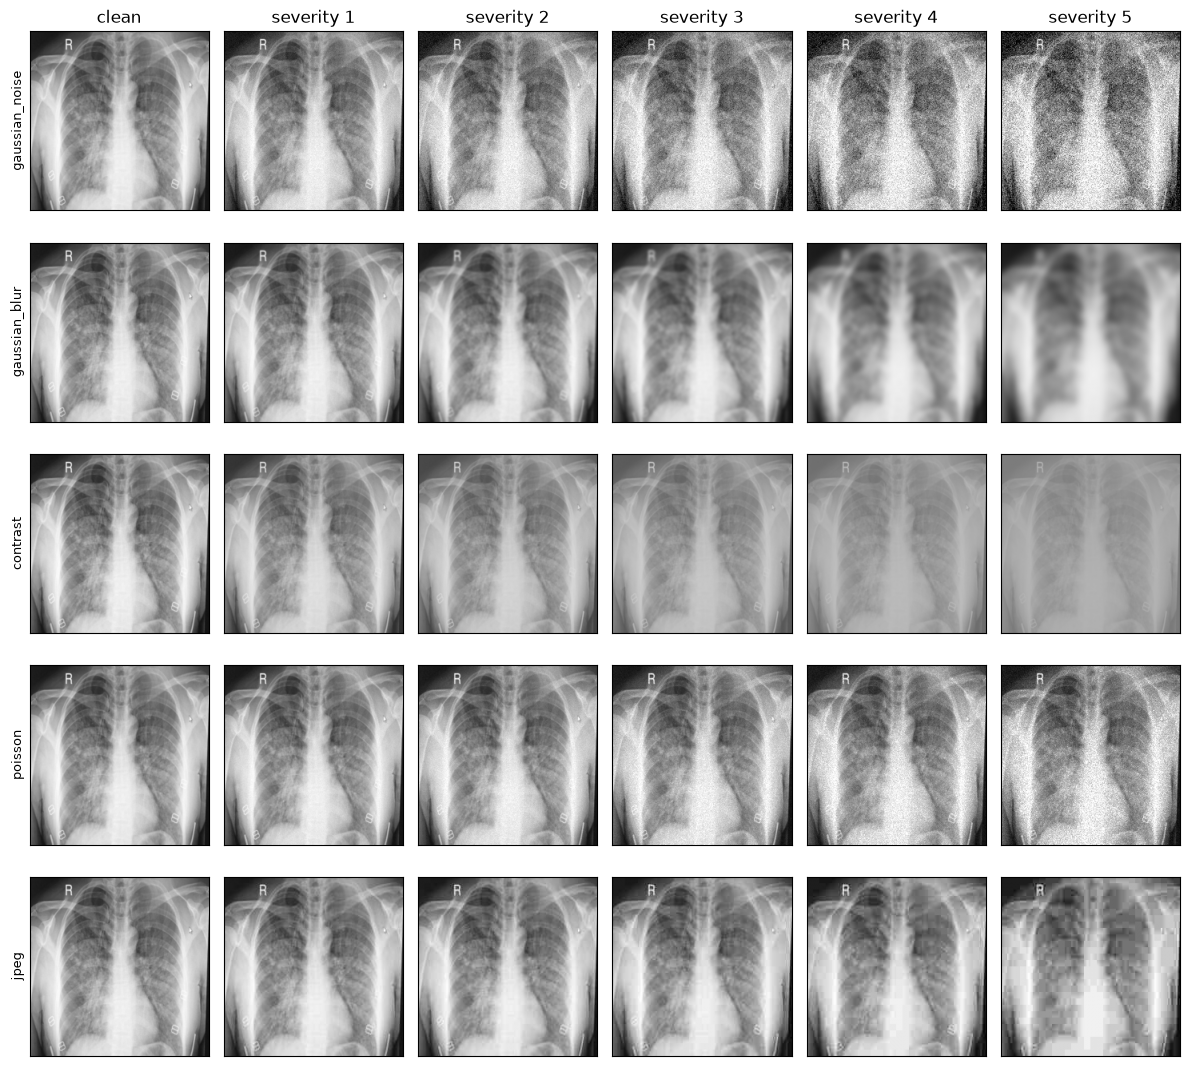

In [3]:
img = images[0]
fig, axes = plt.subplots(len(CORRUPTIONS), len(SEVERITIES), figsize=(12, 2.2 * len(CORRUPTIONS)))
 
for r, name in enumerate(CORRUPTIONS):
    for c, sev in enumerate(SEVERITIES):
        ax = axes[r, c]
        ax.imshow(corrupt(img, name, sev, seed=SEED), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if r == 0:
            ax.set_title("clean" if sev == 0 else f"severity {sev}")
        if c == 0:
            ax.set_ylabel(name, fontsize=9)
 
fig.tight_layout()
plt.show()

### Zoomed Crops

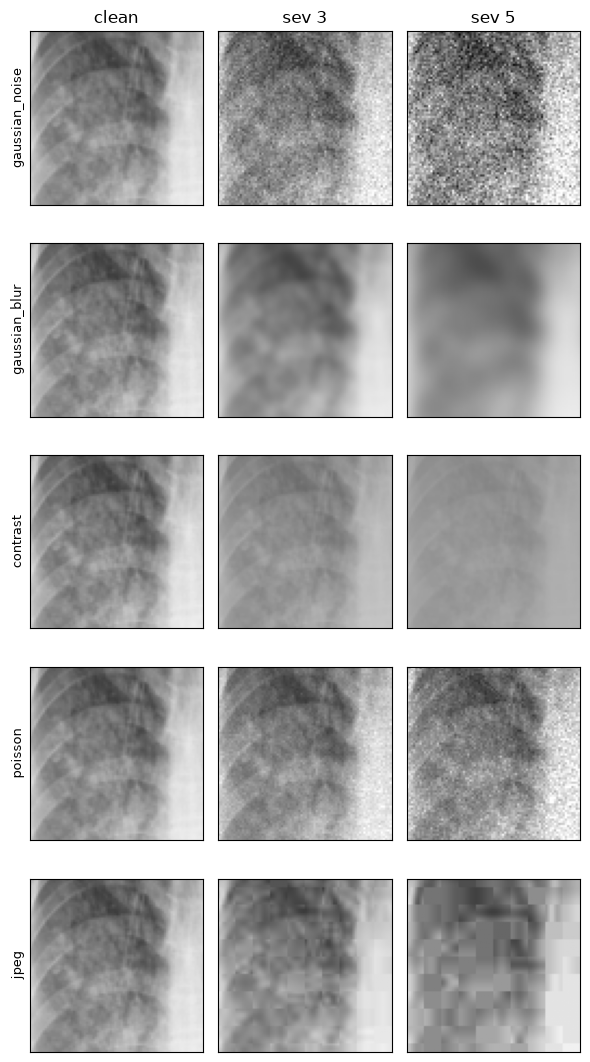

In [4]:
crop = (slice(60, 140), slice(40, 120))
 
fig, axes = plt.subplots(len(CORRUPTIONS), 3, figsize=(6, 2.2 * len(CORRUPTIONS)))
for r, name in enumerate(CORRUPTIONS):
    for c, sev in enumerate((0, 3, 5)):
        ax = axes[r, c]
        ax.imshow(corrupt(img, name, sev, seed=SEED)[crop], cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if r == 0:
            ax.set_title("clean" if sev == 0 else f"sev {sev}")
        if c == 0:
            ax.set_ylabel(name, fontsize=9)
fig.tight_layout()
plt.show()

### How each severity alters the image

Measure pixel difference.

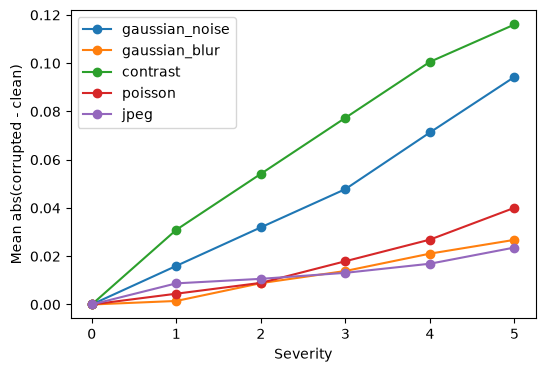

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
for name in CORRUPTIONS:
    diffs = [
        np.mean([np.abs(corrupt(im, name, s, seed=SEED) - im / 255).mean() for im in images])
        for s in SEVERITIES
    ]
    ax.plot(list(SEVERITIES), diffs, marker="o", label=name)
 
ax.set_xlabel("Severity")
ax.set_ylabel("Mean abs(corrupted - clean)")
ax.legend()
plt.show()

Measure structure loss.

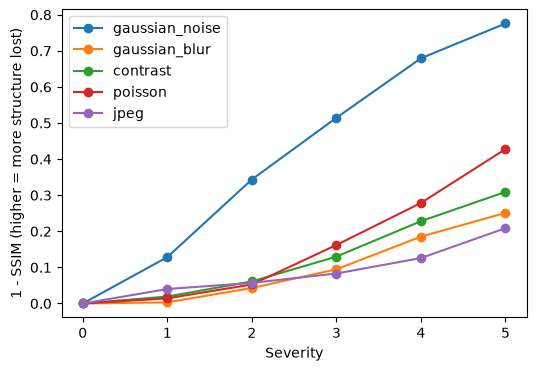

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
for name in CORRUPTIONS:
    scores = [
        np.mean([
            1 - ssim(im / 255, corrupt(im, name, s, seed=SEED), data_range=1.0)
            for im in images
        ])
        for s in SEVERITIES
    ]
    ax.plot(list(SEVERITIES), scores, marker="o", label=name)

ax.set_xlabel("Severity")
ax.set_ylabel("1 - SSIM (higher = more structure lost)")
ax.legend()
plt.show()